# Other BVOC check: how much of the MEGAN signal is not ISOP or MTERP?

The fBVOC runs keep only ISOP and MTERP and switch off every other MEGAN compound. This notebook sums the CLM `MEG_*` emissions in CTRL and LCC **over the land-cover-modified cells only** and asks two questions:

1. **Share of total:** what fraction of the emissions are "other" compounds? This sets the size of what the fBVOC runs remove.
2. **Share of the change:** what fraction of ΔE (LCC − CTRL) comes from "other" compounds? This is what an ISOP/MTERP-only BVOC definition misses.

Both are computed by **mass** and by **OH reactivity** (emitted moles × k_OH at 298 K). Mass alone overweights slow reactants such as methanol and CO.

**Domain:** the cells flagged in `modified_cells.nc` (any natural-PFT change between the baseline and LCC surface files, built by `equilibrium.build_modified_cells`). All totals, shares and the key figure use this domain; the maps show the surroundings for context.

**Inputs:** CLM h0 monthly files only. `MEG_<name>` fields are active by default, kg m⁻² s⁻¹, gridcell average with lake and urban set to 0 (CTSM `VOCEmissionMod.F90`, NorESM tag `release-clm5.0.14-Nor_v1.0.7`).

## Conclusions

## Non-isoprene/monoterpene BVOCs in the LCC experiment (LCC_PD − CTRL_PD)

**Domain:** the 1161 land-cover-modified cells (24.4 million km² of land), 9 complete years (2001–2009). Emissions are the CLM `MEG_*` fluxes. "Other" = all MEGAN compounds except ISOP and MTERP: BCARY plus 16 oxygenated and small hydrocarbon species. These are the compounds switched off in the fBVOC runs.

**Metrics:** emitted mass, and OH reactivity of the emissions (emitted moles × k_OH at 298 K, with rate constants from the run's `chem_mech.in`). OH reactivity is the relevant metric for gas-phase chemistry. Mass is dominated by slow-reacting species and overstates their importance.

### Key numbers

| Group | Share of CTRL emissions (mass) | Share of CTRL emissions (OH reactivity) | ΔE (Tg/yr) | ΔE (% of CTRL group) | ΔOH reactivity, % of CTRL total (mean ± 2 SE, 9 yr) |
|---|---|---|---|---|---|
| ISOP  | 23 % | 66 % | +0.322 | +7.9 % | +5.21 ± 0.45 |
| MTERP | 26 % | 19 % | +0.118 | +2.6 % | +0.50 ± 0.12 |
| Other | 51 % | 15 % | −0.011 | −0.1 % | −0.14 ± 0.09 |
| Total | — | — | +0.428 | +2.4 % | +5.58 |

### Interpretation

1. **The "other" compounds are large by mass but small by OH reactivity.** They are about half of the emitted mass in the modified cells, but only about 15 % of the emitted OH reactivity.
2. **The land-cover change barely alters them.** Their emissions change by −0.1 % (−0.011 Tg/yr). This net change is small because increases and decreases in different cells largely cancel, as the mass Δ map shows.
3. **The BVOC signal of the land-cover change is effectively ISOP + MTERP.** By OH reactivity:
   - ISOP gives about 94 % of the net change and MTERP about 9 %.
   - "Other" gives −3 %, a slight offset. It comes mainly from small decreases in propene, BIGENE and ethene.
   - The ISOP and MTERP increases are positive in every year. The "other" change is close to zero; its 2-SE range (−0.05 to −0.23 %) excludes zero only narrowly.
4. **Implication for the fBVOC design** *(inference)*. The fBVOC runs remove about 15 % of the emitted OH reactivity in this region, so the background oxidant field of the fBVOC members is biased. However, the land-cover change leaves the "other" compounds almost unchanged. So a BVOC contrast that differences out the fBVOC members, as in O1, loses only about 3 % of the OH-reactivity change, assuming the responses add linearly.
5. **Aerosol pathway.** In this NorESM2.3 mechanism, only MTERP (via `SOA_LV` and `SOA_SV`) and ISOP (via `SOA_SV`) produce SOA. The "other" compounds therefore affect aerosol only indirectly, through oxidants (OH, O₃, NOx). Given point 3, this indirect channel is small.

### Spatial pattern (maps)

- **ISOP and MTERP change in opposite directions in different sectors** of the modified region. The net increases are therefore the residual of larger regional changes of both signs, not uniform increases.
- **The OH-reactivity-weighted maps share one colour scale across groups.** On that scale, "Other" is pale throughout, both in CTRL emissions and in the change.
- **Emission changes also appear outside the modified cells.** They are excluded here by construction. *(Inference)* Since the nudging is wind-only, they are probably responses of emissions to temperature and radiation rather than land cover.

### Caveats

- **Ozonolysis and NO₃ reactions are not weighted.** Since BCARY reacts fast with O₃, its importance is underestimated.
- **k_OH is evaluated at 298 K**, warmer than boreal conditions; the relative weights shift somewhat at lower temperature.
- **Masses are CLM compound masses.** CAM receives moles and lumps compounds into its species, so CAM-side masses differ slightly (e.g. tricyclene is counted as BIGALK).
- **The mask flags any natural-PFT change greater than 10⁻⁶ percentage points.** Cells with negligible change dilute the per-area signal, though not the absolute totals in Tg/yr.
- **The global ISOP change has the opposite sign.** In an earlier run of this notebook over all land, ISOP decreased by 7.6 Tg/yr, compared with +0.32 Tg/yr inside the modified cells. The decrease therefore comes from outside the modified region and needs a separate explanation.

In [1]:
import glob
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

# ---------------------------------------------------------------- EDIT
ARCHIVE = "/cluster/work/users/adelez/archive"
RUNS = {
    "CTRL_PD": "NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20260925",
    "LCC_PD":  "NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261005",
    # "CTRL_FUT": "NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20260925",
    # "LCC_FUT":  "NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261005",
}
PAIRS = [("CTRL_PD", "LCC_PD")]          # (reference, perturbed); add ("CTRL_FUT", "LCC_FUT")
SPINUP_MONTHS = 12                         # dropped at the start of each run
MASK_FILE = ("/cluster/home/adelez/BOREAL-FOREST-EXPANSION/diagnostics/"
             "check-simulation-equilibrium/lcc-modified-cells/modified_cells.nc")
MAP_LAT_MIN = 40.0                         # southern edge of the maps
T_REF, P_REF = 298.0, 101325.0             # for k_OH (surface conditions)
# ----------------------------------------------------------------------

def h0_files(case):
    files = sorted(glob.glob(f"{ARCHIVE}/{case}/lnd/hist/{case}.clm2.h0.*.nc"))
    if not files:
        raise FileNotFoundError(f"No CLM h0 files for {case}")
    return files

## Compound table

Taken from your `megan_specifier`. Molar masses are standard values I typed in (not read from the model). The CAM species decides which k_OH applies.

In [2]:
# MEGAN name: (CAM species, molar mass g/mol)
C10H16, C15H24 = 136.23, 204.35
COMPOUNDS = {
    "isoprene": ("ISOP", 68.12),
    **{n: ("MTERP", C10H16) for n in [
        "pinene_a", "carene_3", "thujene_a", "terpinolene", "bornene", "fenchene_a",
        "ocimene_al", "pinene_b", "sabinene", "camphene", "limonene", "phellandrene_a",
        "terpinene_g", "terpinene_a", "phellandrene_b", "myrcene", "ocimene_t_b", "ocimene_c_b"]},
    "2met_styrene": ("MTERP", 118.18), "cymene_p": ("MTERP", 134.22), "cymene_o": ("MTERP", 134.22),
    **{n: ("BCARY", C15H24) for n in [
        "caryophyllene_b", "bergamotene_a", "bisabolene_b", "farnescene_b", "humulene_a"]},
    "methanol": ("CH3OH", 32.04), "ethanol": ("C2H5OH", 46.07), "formaldehyde": ("CH2O", 30.03),
    "acetaldehyde": ("CH3CHO", 44.05), "acetic_acid": ("CH3COOH", 60.05), "acetone": ("CH3COCH3", 58.08),
    "formic_acid": ("HCOOH", 46.03), "hydrogen_cyanide": ("HCN", 27.03), "carbon_monoxide": ("CO", 28.01),
    "ethane": ("C2H6", 30.07), "ethene": ("C2H4", 28.05), "propane": ("C3H8", 44.10), "propene": ("C3H6", 42.08),
    "pentane": ("BIGALK", 72.15), "hexane": ("BIGALK", 86.18), "heptane": ("BIGALK", 100.20),
    "tricyclene": ("BIGALK", C10H16), "butene": ("BIGENE", 56.11), "toluene": ("TOLUENE", 92.14),
}
assert len(COMPOUNDS) == 46

def group(cam):
    """Three-way split used in the summary."""
    return cam if cam in ("ISOP", "MTERP") else "Other"

## k_OH at 298 K

Rate expressions copied from `pp_tropstrat_mam_oslo/chem_mech.in` and `mozart/mo_usrrxt.F90` in your CAM fork (branch `new-case-set`). CAM convention: Arrhenius `A, B` means k = A·exp(B/T); Troe `k0, n0, kinf, ninf, fc` uses (300/T)ⁿ.

Checked against the `chem_mech.in` from your run: it is identical to `pp_tropstrat_mam_oslo/chem_mech.in` in the fork, apart from blank lines and trailing spaces.

In [3]:
def arr(A, B=0.0, T=T_REF):
    return A * np.exp(B / T)

def troe(k0A, n0, kiA, ni, fc, T=T_REF, P=P_REF):
    M = P / (1.380649e-23 * T) * 1e-6                       # molecules cm-3
    k0, ki = k0A * (300 / T) ** n0 * M, kiA * (300 / T) ** ni
    return k0 / (1 + k0 / ki) * fc ** (1 / (1 + np.log10(k0 / ki) ** 2))

def k_co(T=T_REF, P=P_REF):                                  # CO_OH_M + usr_CO_OH_b
    M = P / (1.380649e-23 * T) * 1e-6
    ki, ko = 2.1e9 * (T / 300) ** 6.1, 1.5e-13
    t1 = ko / (ki / M)
    b = ko / (1 + t1) * 0.6 ** (1 / (1 + np.log10(t1) ** 2))
    return troe(5.9e-33, 1, 1.1e-12, -1.3, 0.6, T, P) + b

K_OH = {                                   # cm3 molecule-1 s-1; chem_mech.in reaction label
    "ISOP":     arr(2.54e-11, 410),        # ISOP_OH
    "MTERP":    arr(1.2e-11, 440),         # MTERP_OH
    "BCARY":    arr(2e-10),                # BCARY_OH
    "CH3OH":    arr(2.9e-12, -345),        # CH3OH_OH
    "C2H5OH":   arr(6.9e-12, -230),        # C2H5OH_OH
    "CH2O":     arr(5.5e-12, 125),         # CH2O_OH
    "CH3CHO":   arr(4.63e-12, 350),        # CH3CHO_OH
    "CH3COOH":  arr(7e-13),                # CH3COOH_OH
    "CH3COCH3": 3.82e-11 * np.exp(-2000 / T_REF) + 1.33e-13,   # usr_CH3COCH3_OH
    "HCOOH":    arr(4e-13),                # HCOOH_OH
    "HCN":      troe(4.28e-33, 0, 9.3e-15, -4.42, 0.8),        # HCN_OH
    "CO":       k_co(),                    # CO_OH_M + usr_CO_OH_b
    "C2H6":     arr(7.66e-12, -1020),      # C2H6_OH
    "C2H4":     troe(8.6e-29, 3.1, 9e-12, 0.85, 0.48),         # tag_C2H4_OH
    "C3H8":     arr(8.7e-12, -615),        # C3H8_OH
    "C3H6":     troe(8e-27, 3.5, 3e-11, 0, 0.5),               # tag_C3H6_OH
    "BIGALK":   arr(3.5e-12),              # BIGALK_OH
    "BIGENE":   arr(5.4e-11),              # BIGENE_OH
    "TOLUENE":  arr(1.7e-12, 352),         # TOLUENE_OH
}
pd.Series(K_OH, name="k_OH(298 K)").map("{:.2e}".format).to_frame().T

,ISOP,MTERP,BCARY,CH3OH,C2H5OH,CH2O,CH3CHO,CH3COOH,CH3COCH3,HCOOH,HCN,CO,C2H6,C2H4,C3H8,C3H6,BIGALK,BIGENE,TOLUENE
k_OH(298 K),1.01e-10,5.25e-11,2.00e-10,9.11e-13,3.19e-12,8.37e-12,1.50e-11,7.00e-13,1.79e-13,4.00e-13,7.49e-15,2.37e-13,2.50e-13,8.07e-12,1.10e-12,2.87e-11,3.50e-12,5.40e-11,5.54e-12


## Modified-cell mask and annual totals

The mask is matched to the CLM grid by coordinates (exact match, longitude wrap allowed), as in `equilibrium.modified_mask`. It is never regridded.

In [4]:
def load_mask(path, lat, lon):
    """Modified-cell mask on the CLM grid; raises if the grids differ."""
    with xr.open_dataset(path) as m:
        m = m.load()
    if not np.isin(m["modified"], [0, 1]).all() or not m["modified"].any():
        raise ValueError("Invalid or empty modified-cell mask")
    def match(source, target, cyclic=False):
        dist = abs(np.asarray(target)[:, None] - np.asarray(source)[None, :])
        if cyclic:
            dist = np.minimum(dist, 360 - dist)
        idx = dist.argmin(axis=1)
        if (len(source) != len(target) or len(set(idx)) != len(idx)
                or np.any(dist[np.arange(len(target)), idx] > 1e-4)):
            raise ValueError("Mask and CLM grids differ; regridding needs an explicit decision.")
        return idx
    i = match(m["lat"].values, lat.values)
    j = match(m["lon"].values % 360, lon.values % 360, cyclic=True)
    return xr.DataArray(m["modified"].values[np.ix_(i, j)].astype(bool),
                        dims=("lat", "lon"), coords={"lat": lat, "lon": lon})

def keep_meg(d):
    """Keep only the MEG_* fields, so files are concatenated along time and nothing else."""
    return d[[v for v in d.data_vars if v.startswith("MEG_")]]

def month_info(times):
    """Seconds and calendar year of each monthly mean.

    CLM stamps monthly means at the end of the interval (e.g. 0001-02-01 for January).
    Shifting back one day lands inside the averaged month whether the stamp is the end
    or the middle of the interval; days_in_month then follows the model calendar."""
    inside = times.to_index().shift(-1, "D")
    sec = xr.DataArray(np.asarray(inside.days_in_month) * 86400.0, dims="time", coords={"time": times})
    year = xr.DataArray(np.asarray(inside.year), dims="time", coords={"time": times})
    return sec, year

def load_case(case):
    """Per compound: Tg per calendar year over modified cells, and mean map (kg m-2 yr-1)."""
    files = h0_files(case)
    ds = xr.open_mfdataset(files, combine="nested", concat_dim="time", preprocess=keep_meg)
    ds = ds.sortby("time")
    dup = ds.indexes["time"].duplicated()
    if dup.any():
        print(f"[{case}] dropping {dup.sum()} duplicated time stamps")
        ds = ds.isel(time=~dup)
    ds = ds.isel(time=slice(SPINUP_MONTHS, None))

    sec, year = month_info(ds["time"])
    counts = pd.Series(year.values).value_counts()
    full = sorted(counts.index[counts == 12])
    keep = year.isin(full)
    ds, sec, year = ds.isel(time=keep), sec[keep], year[keep]
    print(f"[{case}] complete years used: {full[0]}-{full[-1]} ({len(full)})")

    found = sorted(v[4:] for v in ds.data_vars)
    missing, extra = sorted(set(COMPOUNDS) - set(found)), sorted(set(found) - set(COMPOUNDS))
    if missing or extra:
        print(f"[{case}] missing: {missing}  not in table: {extra}")

    with xr.open_dataset(files[0]) as f0:                               # static fields
        if f0["area"].attrs.get("units", "km^2") not in ("km^2", "km2"):
            raise ValueError(f"unexpected area units: {f0['area'].attrs.get('units')}")
        land_m2 = (f0["area"] * 1e6 * f0["landfrac"]).fillna(0).load()  # m2 of land per cell
        mask = load_mask(MASK_FILE, f0["lat"], f0["lon"])
    w = land_m2.where(mask, 0)

    per_year, maps = {}, {}
    for name in (n for n in found if n in COMPOUNDS):
        flux = ds[f"MEG_{name}"].fillna(0) * sec                          # kg m-2 per month
        per_year[name] = ((flux * w).sum(("lat", "lon")).groupby(year).sum() / 1e9).to_series()
        maps[name] = flux.sum("time") / len(full)                         # kg m-2 yr-1 (per m2 land)
    maps = xr.Dataset(maps).compute()
    return pd.DataFrame(per_year), maps, mask, land_m2

yearly, maps = {}, {}
for alias, case in RUNS.items():
    yearly[alias], maps[alias], MASK, LAND_M2 = load_case(case)
totals = {alias: y.mean() for alias, y in yearly.items()}               # Tg/yr, modified cells
print(f"Modified cells: {int(MASK.sum())}, land area {float(LAND_M2.where(MASK).sum()) / 1e12:.2f} million km2")

[NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20260925] complete years used: 2001-2009 (9)
[NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261005] complete years used: 2001-2009 (9)
Modified cells: 1161, land area 24.42 million km2


## Summary by group

Mass in Tg/yr. OH reactivity is emitted moles × k_OH, shown as a share only (its absolute value has no simple unit meaning).

In [5]:
def by_group(tot):
    t = tot.rename("Tg").to_frame()
    t["cam"] = [COMPOUNDS[n][0] for n in t.index]
    t["group"] = t["cam"].map(group)
    t["OHR"] = t["Tg"] * 1e12 / [COMPOUNDS[n][1] for n in t.index] * t["cam"].map(K_OH)
    return t

def summary(ref, pert):
    a, b = by_group(totals[ref]), by_group(totals[pert])
    out = {}
    for metric in ("Tg", "OHR"):
        ga, gb = a.groupby("group")[metric].sum(), b.groupby("group")[metric].sum()
        d = gb - ga
        out[(metric, ref)] = ga
        out[(metric, pert)] = gb
        out[(metric, "Δ")] = d
        out[(metric, f"share of {ref}")] = ga / ga.sum()
        out[(metric, "share of Δ")] = d / d.sum()
    s = pd.DataFrame(out).reindex(["ISOP", "MTERP", "Other"])
    s.loc["Total"] = s.sum()
    s.loc["Total", [c for c in s.columns if c[1].startswith("share")]] = np.nan
    return s

for ref, pert in PAIRS:
    print(f"\n=== {pert} − {ref}, modified cells ===")
    s = summary(ref, pert)
    fmt = {c: ("{:.1%}" if c[1].startswith("share") else
               "{:.3f}" if c[0] == "Tg" else "{:.2e}") for c in s.columns}
    display(s.style.format(fmt, na_rep=""))


=== LCC_PD − CTRL_PD, modified cells ===


**Read "share of Δ" with care.** If ΔE of ISOP and MTERP have opposite signs, the total Δ can be small and the shares can exceed 100 % or be negative. In that case compare the absolute Δ values instead.

## Which "other" compounds carry the change?

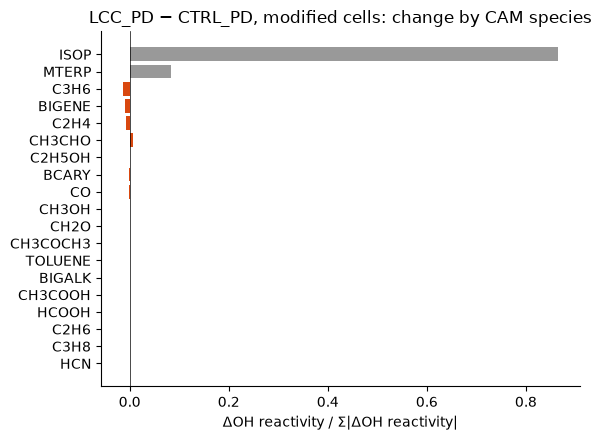

In [6]:
for ref, pert in PAIRS:
    a, b = by_group(totals[ref]), by_group(totals[pert])
    d = (b["OHR"] - a["OHR"]).groupby(a["cam"]).sum()
    d = d / (b["OHR"] - a["OHR"]).abs().sum()                    # normalised: Σ|Δ| = 1
    d = d.reindex(d.abs().sort_values().index)
    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.barh(d.index, d.values, color=["0.6" if c in ("ISOP", "MTERP") else "#D9480F" for c in d.index])
    ax.axvline(0, color="k", lw=0.5)
    ax.set_xlabel("ΔOH reactivity / Σ|ΔOH reactivity|")
    ax.set_title(f"{pert} − {ref}, modified cells: change by CAM species")
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()

## Key figure: what fBVOC removes vs. what LCC changes

Domain: modified cells. Left: each group's share of CTRL emissions and of the LCC − CTRL change, by mass and by OH reactivity. Right: the change in OH reactivity, with the spread across years. The runs are nudged to the same winds, so each year of LCC is compared with the same year of CTRL.

Mixed signs in Δ: stacked shares not meaningful, see the right panel only.
ΔOH reactivity, % of CTRL total (mean ± 2 SE over years):
ISOP     +5.21 ± 0.45
MTERP    +0.50 ± 0.12
Other    -0.14 ± 0.09


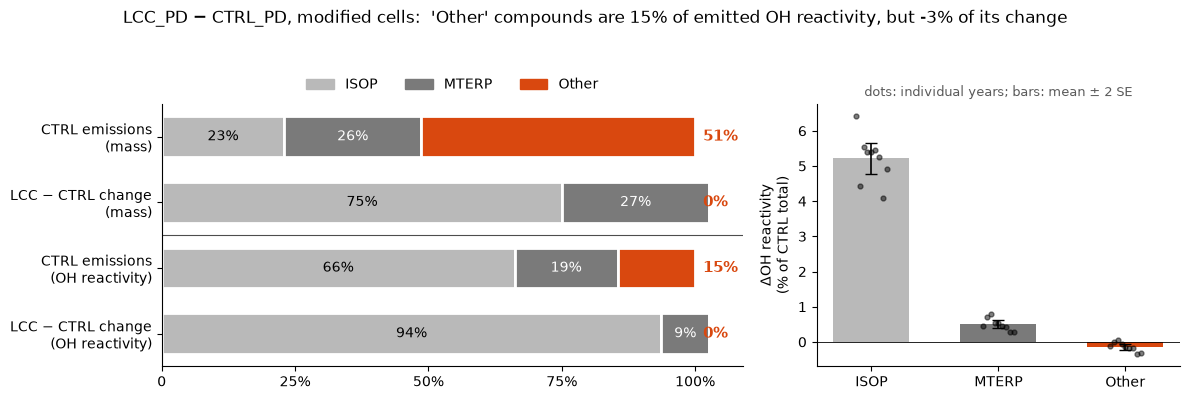

In [11]:
COL = {"ISOP": "#B9B9B9", "MTERP": "#7A7A7A", "Other": "#D9480F"}
GROUPS = ["ISOP", "MTERP", "Other"]

def yearly_by_group(alias, metric):
    y = yearly[alias]
    cam = pd.Series({n: COMPOUNDS[n][0] for n in y.columns})
    if metric == "OHR":
        y = y * 1e12 / pd.Series({n: COMPOUNDS[n][1] for n in y.columns}) * cam.map(K_OH)
    return y.T.groupby(cam.map(group)).sum().T[GROUPS]                  # years x group

def key_figure(ref, pert):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})

    # left: 100 % stacked shares
    rows = []
    for metric, mlabel in (("Tg", "mass"), ("OHR", "OH reactivity")):
        yr, yp = yearly_by_group(ref, metric), yearly_by_group(pert, metric)
        e, d = yr.mean(), (yp - yr).mean()
        rows += [(f"CTRL emissions\n({mlabel})", e), (f"LCC − CTRL change\n({mlabel})", d)]
    if any((r[1] < 0).any() for r in rows):
        print("Mixed signs in Δ: stacked shares not meaningful, see the right panel only.")
    labels = [r[0] for r in rows][::-1]
    for i, (_, v) in enumerate(rows[::-1]):
        frac, left = (v / v.sum()).clip(lower=0), 0.0
        for g in GROUPS:
            a1.barh(i, frac[g], left=left, height=0.62, color=COL[g],
                    edgecolor="white", linewidth=2)
            if g == "Other":                                             # always labelled, outside
                a1.text(1.015, i, f"{frac[g]:.0%}", ha="left", va="center",
                        fontsize=11, color=COL[g], fontweight="bold")
            elif frac[g] > 0.06:
                a1.text(left + frac[g] / 2, i, f"{frac[g]:.0%}", ha="center", va="center",
                        fontsize=10, color="white" if g != "ISOP" else "black")
            left += frac[g]
    a1.set_yticks(range(len(labels)), labels)
    a1.axhline(1.5, color="0.3", lw=0.8)
    a1.set_xlim(0, 1.09); a1.set_xticks([0, .25, .5, .75, 1], ["0", "25%", "50%", "75%", "100%"])
    a1.spines[["top", "right"]].set_visible(False)
    a1.legend([plt.Rectangle((0, 0), 1, 1, color=COL[g]) for g in GROUPS], GROUPS,
              ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)

    # right: ΔOHR per group as % of CTRL total OHR, with year-to-year spread
    yr, yp = yearly_by_group(ref, "OHR"), yearly_by_group(pert, "OHR")
    dd = (yp - yr).div(yr.sum(axis=1), axis=0) * 100                    # % of CTRL total, per year
    m, sem = dd.mean(), dd.std(ddof=1) / np.sqrt(len(dd))
    x = np.arange(len(GROUPS))
    a2.bar(x, m[GROUPS], color=[COL[g] for g in GROUPS], width=0.6)
    for xi, g in zip(x, GROUPS):
        a2.plot(np.full(len(dd), xi) + np.linspace(-.12, .12, len(dd)), dd[g], "o",
                ms=3.5, color="black", alpha=.5, zorder=3)
        a2.errorbar(xi, m[g], yerr=2 * sem[g], color="black", capsize=4, lw=1.2, zorder=4)
    a2.axhline(0, color="black", lw=0.6)
    a2.set_xticks(x, GROUPS)
    a2.set_ylabel("ΔOH reactivity\n(% of CTRL total)")
    a2.set_title("dots: individual years; bars: mean ± 2 SE", fontsize=9, color="0.35")
    a2.spines[["top", "right"]].set_visible(False)

    e_ohr = yearly_by_group(ref, "OHR").mean()
    d_ohr = (yp - yr).mean()
    fig.suptitle(f"{pert} − {ref}, modified cells:  'Other' compounds are "
                 f"{e_ohr['Other'] / e_ohr.sum():.0%} of emitted OH reactivity, but "
                 f"{d_ohr['Other'] / d_ohr.sum():.0%} of its change", fontsize=12, y=1.04)
    fig.tight_layout()
    return fig, dd

for ref, pert in PAIRS:
    fig, dd = key_figure(ref, pert)
    print("ΔOH reactivity, % of CTRL total (mean ± 2 SE over years):")
    print((dd.mean().map("{:+.2f}".format) + " ± " + (2 * dd.std(ddof=1) / np.sqrt(len(dd))).map("{:.2f}".format)).to_string())

## Maps: emissions and their change

Rows: ISOP, MTERP, "Other". Columns: CTRL emissions and LCC − CTRL. Black outline: modified cells; grey: model land edge (no coastline download needed). Fluxes are per m² of land (as CLM writes them), averaged over complete years.

Two versions:
- **Mass** (g m⁻² yr⁻¹): what is emitted.
- **Isoprene-equivalent** (g m⁻² yr⁻¹): OH reactivity expressed as the isoprene mass with the same OH reactivity, i.e. moles × k_OH / k_OH(ISOP) × M(ISOP). This puts all three rows on the scale that matters for OH.

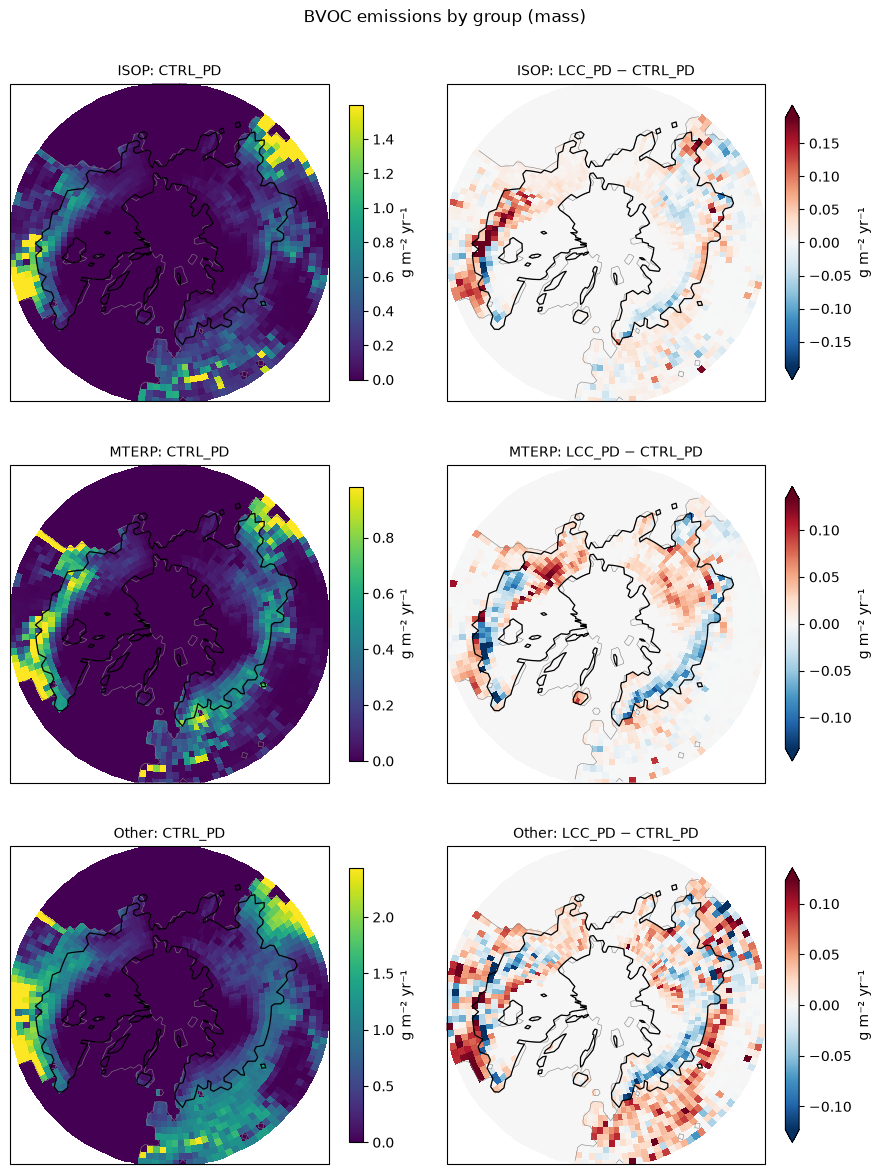

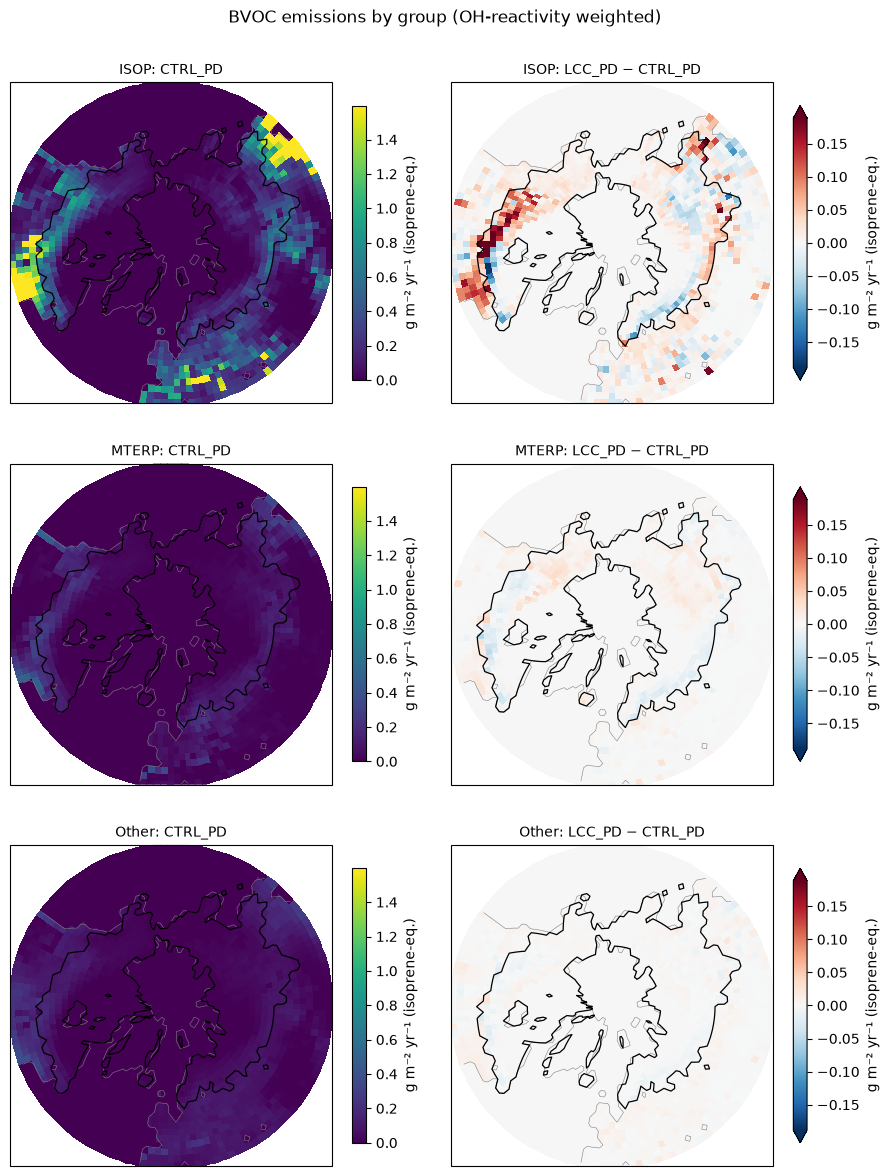

In [8]:
try:
    import cartopy.crs as ccrs
    HAVE_CARTOPY = True
except ImportError:
    HAVE_CARTOPY = False
    print("cartopy not found: plain lat-lon maps")

def group_maps(alias, metric):
    """Sum per-compound maps (kg m-2 yr-1) into ISOP / MTERP / Other, in g m-2 yr-1."""
    out = {g: 0 for g in GROUPS}
    for name, da in maps[alias].data_vars.items():
        cam = COMPOUNDS[name][0]
        f = da * 1e3                                                      # g m-2 yr-1
        if metric == "isop_eq":
            f = f / COMPOUNDS[name][1] * K_OH[cam] / K_OH["ISOP"] * COMPOUNDS["isoprene"][1]
        out[group(cam)] = out[group(cam)] + f
    return xr.Dataset(out).sel(lat=slice(MAP_LAT_MIN, 90))

def add_cyclic(da):
    """Repeat the first longitude at +360 so polar plots have no gap."""
    first = da.isel(lon=0).assign_coords(lon=float(da.lon[0]) + 360)
    return xr.concat([da, first], dim="lon")

def map_panel(fig, pos, da, cmap, vmin, vmax, title):
    da = add_cyclic(da)
    m = add_cyclic(MASK.sel(lat=slice(MAP_LAT_MIN, 90)).astype(float))
    lf = add_cyclic((LAND_M2 > 0).sel(lat=slice(MAP_LAT_MIN, 90)).astype(float))
    if HAVE_CARTOPY:
        ax = fig.add_subplot(*pos, projection=ccrs.NorthPolarStereo())
        ax.set_extent([-180, 180, MAP_LAT_MIN, 90], ccrs.PlateCarree())
        kw = dict(transform=ccrs.PlateCarree())
    else:
        ax, kw = fig.add_subplot(*pos), {}
    pm = ax.pcolormesh(da.lon, da.lat, da, cmap=cmap, vmin=vmin, vmax=vmax, shading="nearest", **kw)
    ax.contour(lf.lon, lf.lat, lf, levels=[0.5], colors="0.5", linewidths=0.4, **kw)   # model coastline
    ax.contour(m.lon, m.lat, m, levels=[0.5], colors="black", linewidths=0.9, **kw)
    ax.set_title(title, fontsize=10)
    return ax, pm

def emission_maps(ref, pert, metric):
    a, b = group_maps(ref, metric), group_maps(pert, metric)
    unit = "g m⁻² yr⁻¹" + (" (isoprene-eq.)" if metric == "isop_eq" else "")
    shared = metric == "isop_eq"                                         # one scale for all rows
    def scales(g):
        ctrl, diff = a[g], b[g] - a[g]
        return float(ctrl.quantile(0.99)), float(abs(diff).where(MASK).quantile(0.99)) or float(abs(diff).max())
    if shared:
        vmax_all = max(scales(g)[0] for g in GROUPS)
        dmax_all = max(scales(g)[1] for g in GROUPS)
    fig = plt.figure(figsize=(9, 12))
    for r, g in enumerate(GROUPS):
        ctrl, diff = a[g], b[g] - a[g]
        vmax, dmax = (vmax_all, dmax_all) if shared else scales(g)
        ax, pm = map_panel(fig, (3, 2, 2 * r + 1), ctrl, "viridis", 0, vmax, f"{g}: {ref}")
        fig.colorbar(pm, ax=ax, shrink=0.75, label=unit)
        ax, pm = map_panel(fig, (3, 2, 2 * r + 2), diff, "RdBu_r", -dmax, dmax, f"{g}: {pert} − {ref}")
        fig.colorbar(pm, ax=ax, shrink=0.75, label=unit, extend="both")
    fig.suptitle(f"BVOC emissions by group ({'mass' if metric == 'mass' else 'OH-reactivity weighted'})", y=0.995)
    fig.tight_layout()
    return fig

for ref, pert in PAIRS:
    emission_maps(ref, pert, "mass")
    emission_maps(ref, pert, "isop_eq")

**Colour scales.** In the isoprene-equivalent figure all rows share one scale per column, so colour intensity is directly comparable: a pale "Other" row means "Other" matters little for OH. In the mass figure each panel has its own scale (99th percentile; for Δ, of |Δ| in the modified cells), because the groups differ by orders of magnitude; compare those rows by their colour-bar ranges.

## How to read it

- **"Other" share of Δ is small by OH reactivity** (a few %): the BVOC contrast is effectively ISOP + MTERP for gas-phase chemistry.
- **It is not small:** the fBVOC runs remove a non-negligible chemical signal, and the D1 artifact needs to be quantified.
- **Aerosol:** in your run's `chem_mech.in` the NorESM SOA reactions (`SOA_LV`, `SOA_SV`) use only MTERP and ISOP, so the "other" compounds affect aerosol only indirectly, through oxidants.

**Not covered here:**
- **Ozonolysis.** BCARY and MTERP also react with O₃; weighting by OH reactivity alone underweights BCARY.
- **Temperature.** k_OH is fixed at 298 K; at boreal temperatures the ratios shift somewhat.
- **Changes outside the modified cells.** Emission changes elsewhere (e.g. from temperature responses) are excluded by construction.